<a href="https://colab.research.google.com/github/AdrianRMCA/Metodos-numericos-1/blob/main/Diferencias%20divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Fórmula de las diferencias divididas de Newton

El **método de diferencias divididas de Newton** permite construir un polinomio de interpolación a partir de un conjunto de puntos conocidos de una función. Para obtener los coeficientes del polinomio se utiliza una tabla de diferencias divididas.

### Algoritmo 3.2

Para obtener los coeficientes de las diferencias divididas del polinomio de interpolación $P$ en los $(n+1)$ números distintos $x_0,x_1,\ldots,x_n$, para la función $f$:

**ENTRADA:** Los números $x_0,x_1,\ldots,x_n$; valores $f(x_0),f(x_1),\ldots,f(x_n)$ conforme $F_{0,0},F_{1,0},\ldots,F_{n,0}$.

**SALIDA:** Los números $F_{0,0},F_{1,1},\ldots,F_{n,n}$, donde:

$$
P_n(x)=F_{0,0}+\sum_{i=1}^{n}F_{i,i}\prod_{j=0}^{i-1}(x-x_j)
$$

$$
F_{i,j}=f[x_{i-j},\ldots,x_i]
$$

**Paso 1:** Para $i=1,2,\ldots,n$ y para $j=1,2,\ldots,i$, haga:

$$
F_{i,j}=\frac{F_{i,j-1}-F_{i-1,j-1}}{x_i-x_{i-j}}
$$

**Paso 2:** SALIDA $(F_{0,0},F_{1,1},\ldots,F_{n,n})$.

**PARE.**

La forma de salida del algoritmo 3.2 se puede modificar para producir todas las diferencias divididas, como se muestra en el ejemplo 1.



### Ejemplo 1. Diferencias divididas de Newton

Complete la tabla de diferencias divididas para los datos utilizados en el ejemplo 1 de la sección 3.2 y reproduzca el polinomio de interpolación de grado 4.

Los datos corresponden a la función de Bessel de primera clase de orden cero, $J_0(x)$.

| $x_i$ | $f(x_i)$ |
|---|---|
| 1.0 | 0.7651977 |
| 1.3 | 0.6200860 |
| 1.6 | 0.4554022 |
| 1.9 | 0.2818186 |
| 2.2 | 0.1103623 |

Se busca obtener los coeficientes de las diferencias divididas y construir el polinomio interpolante de Newton.

Posteriormente se evaluará el polinomio en $x=1.5$.


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

def diferencias_divididas(x, y):
    n = len(x)
    F = np.zeros((n, n))

    F[:, 0] = y

    for i in range(1, n):
        for j in range(1, i + 1):
            F[i, j] = (F[i, j-1] - F[i-1, j-1]) / (x[i] - x[i-j])

    return F


In [5]:

x = np.array([1.0, 1.3, 1.6, 1.9, 2.2])

y = np.array([
    0.7651977,
    0.6200860,
    0.4554022,
    0.2818186,
    0.1103623
])

F = diferencias_divididas(x, y)

print("Tabla de diferencias divididas de Newton:\n")

for i in range(len(x)):
    fila = [f"{F[i,j]:.7f}" for j in range(i+1)]
    print(f"x{i} = {x[i]:.1f}  ", fila)

print("\nCoeficientes del polinomio:\n")

for i in range(len(x)):
    print(f"F[{i},{i}] = {F[i,i]:.7f}")


Tabla de diferencias divididas de Newton:

x0 = 1.0   ['0.7651977']
x1 = 1.3   ['0.6200860', '-0.4837057']
x2 = 1.6   ['0.4554022', '-0.5489460', '-0.1087339']
x3 = 1.9   ['0.2818186', '-0.5786120', '-0.0494433', '0.0658784']
x4 = 2.2   ['0.1103623', '-0.5715210', '0.0118183', '0.0680685', '0.0018251']

Coeficientes del polinomio:

F[0,0] = 0.7651977
F[1,1] = -0.4837057
F[2,2] = -0.1087339
F[3,3] = 0.0658784
F[4,4] = 0.0018251



### Construcción del polinomio de Newton

Una vez calculadas las diferencias divididas, se construye el polinomio de interpolación utilizando la siguiente expresión:

$$
P_4(x)=F_{0,0}+F_{1,1}(x-x_0)+F_{2,2}(x-x_0)(x-x_1)
$$

$$
+F_{3,3}(x-x_0)(x-x_1)(x-x_2)
$$

$$
+F_{4,4}(x-x_0)(x-x_1)(x-x_2)(x-x_3)
$$

Sustituyendo los coeficientes obtenidos:

$$
\begin{aligned}
P_4(x) = {} & 0.7651977 - 0.4837057(x-1.0)\\
&-0.1087339(x-1.0)(x-1.3)\\
&+0.0658784(x-1.0)(x-1.3)(x-1.6)\\
&+0.0018251(x-1.0)(x-1.3)(x-1.6)(x-1.9)
\end{aligned}
$$

Se evalúa el polinomio en el punto $x=1.5$ para obtener una aproximación de la función de Bessel.

$$
P_4(1.5)\approx 0.5118200
$$


In [7]:

def evaluar_newton(x_eval, x, F):
    resultado = F[0, 0]
    producto = 1.0

    for i in range(1, len(x)):
        producto *= (x_eval - x[i-1])
        resultado += F[i, i] * producto

    return resultado

x_eval = 1.5

aproximacion = evaluar_newton(x_eval, x, F)
valor_real = jv(0, x_eval)

print(f"Aproximación P4(1.5) = {aproximacion:.7f}")
print(f"Valor real J0(1.5)  = {valor_real:.7f}")
print(f"Error absoluto      = {abs(valor_real-aproximacion):.7f}")


Aproximación P4(1.5) = 0.5118200
Valor real J0(1.5)  = 0.5118277
Error absoluto      = 0.0000077


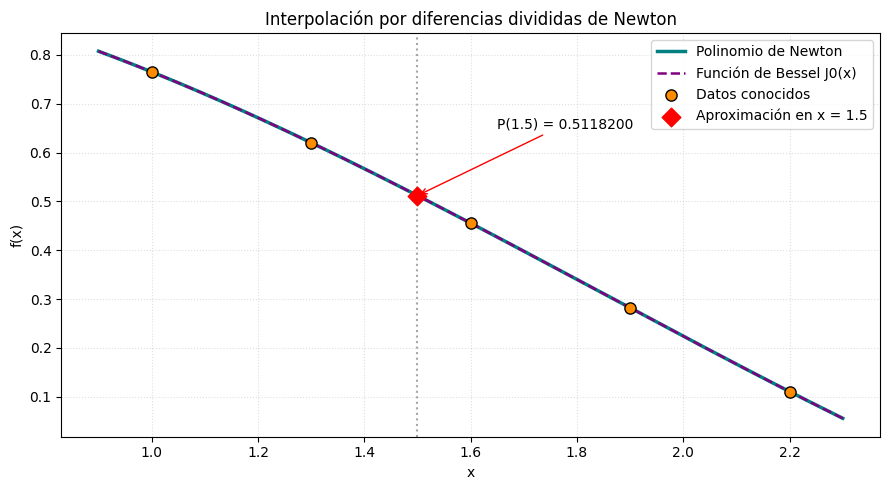

In [8]:

xx = np.linspace(0.9, 2.3, 300)

yy_newton = np.array([
    evaluar_newton(valor, x, F) for valor in xx
])

yy_bessel = jv(0, xx)

plt.figure(figsize=(9, 5))

plt.plot(xx, yy_newton, color='teal',
         linewidth=2.5, label='Polinomio de Newton')

plt.plot(xx, yy_bessel, color='purple',
         linestyle='--', linewidth=1.8,
         label='Función de Bessel J0(x)')

plt.scatter(x, y, color='darkorange', s=65,
            edgecolor='black', zorder=5,
            label='Datos conocidos')

plt.scatter(x_eval, aproximacion, color='red',
            marker='D', s=90, zorder=6,
            label='Aproximación en x = 1.5')

plt.axvline(x_eval, color='gray',
            linestyle=':', alpha=0.7)

plt.annotate(f'P(1.5) = {aproximacion:.7f}',
             xy=(x_eval, aproximacion),
             xytext=(1.65, 0.65),
             arrowprops=dict(arrowstyle='->',
                             color='red'))

plt.title('Interpolación por diferencias divididas de Newton')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True, linestyle=':', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()
